# Ames Mutagenicity: Classical and Graph Neural Network Models

## Part 11 — Manuscript assets

Every figure and every table in the manuscript and its Supporting Information is produced
here from the stored results, so that no quantity shown anywhere is entered by hand. The
notebook reads the CSV files written by Parts 1 to 10 together with the per-molecule arrays
kept in the explain folder, and writes to `figures_ms/` and `tables_ms/`.

A companion file, `tables_ms/manuscript_numbers.csv`, records each quantity quoted in the
text with its value, so that any number can be traced to the analysis that produced it.

**Contents**

1. Environment
2. Shared style
3. Main figures
4. Supporting figures
5. Tables
6. The alert library
7. Attributions on individual molecules
8. Generate everything
9. Collecting the output

*Approximate runtime: fifteen minutes on CPU. No GPU and no model training.*

## 1. Environment

In [1]:
!pip install -q rdkit
!pip install -q xgboost
!pip install -q shap
!pip install -q matplotlib

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 37.4/37.4 MB 57.2 MB/s eta 0:00:00


In [2]:
from google.colab import drive
drive.mount('/content/drive')
import os
WORK = "/content/drive/MyDrive/ames_pipeline"
R, EXPL, DATADIR = f"{WORK}/results", f"{WORK}/explain", f"{WORK}/data"
OUT = f"{WORK}/figures_ms"
os.makedirs(OUT, exist_ok=True)
print("figures ->", OUT)

import glob
need = ["table29_structural_baselines.csv","table12_untrained_null.csv",
        "table42_model_level_attribution.csv","table19b_lift_significance.csv",
        "table46_permutation_repeats.csv","table48_gnnexplainer_settings.csv",
        "table33_structural_regimes.csv","table44_lift_vs_performance.csv",
        "table41_partition_dependence.csv","table58_design_comparison.csv"]
missing = [f for f in need if not os.path.exists(f"{R}/{f}")]
print("missing result files:", missing or "none")
print("explain arrays:", sorted(os.path.basename(p) for p in glob.glob(f"{EXPL}/*.np*"))[:12])

Mounted at /content/drive
figures -> /content/drive/MyDrive/ames_pipeline/figures_ms
missing result files: none
explain arrays: ['control_random_atom_order.npy', 'control_random_feature_weighting.npy', 'control_random_through_bit_map.npy', 'degree_overlaps_primary.npy', 'gnnexplainer_scores.npy', 'masks_default_seed20000.npz', 'masks_default_seed20001.npz', 'masks_default_seed20002.npz', 'masks_default_seed20003.npz', 'masks_default_seed20004.npz', 'masks_longer_seed20000.npz', 'masks_longer_seed20001.npz']


## 2. Shared style

In [3]:
%%writefile /content/msstyle.py
import matplotlib; matplotlib.use("Agg")
import matplotlib.pyplot as plt, numpy as np, pandas as pd
plt.rcParams.update({
    "font.family":"DejaVu Sans","font.size":8,"axes.labelsize":8,"axes.titlesize":8.5,
    "axes.titleweight":"bold","xtick.labelsize":7.5,"ytick.labelsize":7.5,"legend.fontsize":7,
    "axes.spines.top":False,"axes.spines.right":False,"axes.linewidth":.7,
    "xtick.major.width":.7,"ytick.major.width":.7,"figure.dpi":200,"savefig.dpi":400,
    "savefig.bbox":"tight","legend.frameon":False,"lines.linewidth":1.2})
GREEN,ORANGE,BLUE,GREY,PURPLE = "#1a7f37","#e08214","#2166ac","0.55","#7b3294"
COL={"XGBoost":"#0b3d68","RandomForest":"#2166ac","XGBoost_RDKit2D":"#8ec4e0",
     "GCN":"#d6604d","GIN":"#e08214","GAT":"#8c1c13",
     "GIN_noedge":"#f0b366","GAT_noedge":"#c98a84"}
SHORT={"XGBoost":"XGB\nECFP4","RandomForest":"RF\nECFP4","XGBoost_RDKit2D":"XGB\nRDKit-2D",
       "GCN":"GCN","GIN":"GIN","GAT":"GAT","GIN_noedge":"GIN\nno bonds","GAT_noedge":"GAT\nno bonds"}
def panel(ax,l,t): ax.set_title(f"({l}) {t}",loc="left",pad=5)
def save(fig,name,out="/home/claude/figs/out"):
    import os; os.makedirs(out,exist_ok=True)
    for e in ("png","pdf"): fig.savefig(f"{out}/{name}.{e}")
    plt.close(fig)


Writing /content/msstyle.py


## 3. Main figures

*Every arm of the comparison on one axis.*

In [4]:
%%writefile /content/f_ladder.py
from msstyle import *
def build(R,OUT):
    sb=pd.read_csv(f"{R}/table29_structural_baselines.csv").set_index("ranking")
    un=pd.read_csv(f"{R}/table12_untrained_null.csv").set_index("arch")
    mm=pd.read_csv(f"{R}/table42_model_level_attribution.csv")
    ex=pd.read_csv(f"{R}/table19b_lift_significance.csv").set_index("explainer")
    pm=pd.read_csv(f"{R}/table46_permutation_repeats.csv")
    if "fitted" in pm.columns: pm=pm[pm.fitted==True]
    gx=pd.read_csv(f"{R}/table48_gnnexplainer_settings.csv")
    CEIL=float(sb.loc["perfect ranking (ceiling)","lift_mean"])
    DEG=float(sb.loc["degree","lift_mean"])
    g=pm[pm.family=="graph"].lift
    rows=[("Perfect ranking (ceiling)",CEIL,None,"0.45"),
          ("TreeSHAP, fingerprint model",float(ex.loc["XGBoost (TreeSHAP, signed)","lift"]),
           (float(ex.loc["XGBoost (TreeSHAP, signed)","lift_ci_low"]),
            float(ex.loc["XGBoost (TreeSHAP, signed)","lift_ci_high"])),BLUE),
          ("Trained GIN, Integrated Gradients",mm.lift_ig_k30.mean(),
           (mm.lift_ig_k30.mean()-mm.lift_ig_k30.std(ddof=1),
            mm.lift_ig_k30.mean()+mm.lift_ig_k30.std(ddof=1)),ORANGE),
          ("Atom degree (model-free)",DEG,None,GREEN),
          ("Untrained GIN",float(un.loc["gin","mean"]),
           (float(un.loc["gin","p2_5"]),float(un.loc["gin","p97_5"])),"0.5"),
          ("Untrained GAT",float(un.loc["gat","mean"]),
           (float(un.loc["gat","p2_5"]),float(un.loc["gat","p97_5"])),"0.62"),
          ("Untrained GCN",float(un.loc["gcn","mean"]),
           (float(un.loc["gcn","p2_5"]),float(un.loc["gcn","p97_5"])),"0.72"),
          ("GIN, permuted labels",g.mean(),(g.mean()-g.std(ddof=1),g.mean()+g.std(ddof=1)),"#c9a227"),
          ("Chance",float(sb.loc["random atom order","lift_mean"]),None,"0.3"),
          ("GNNExplainer",gx.lift.mean(),
           (gx.lift.mean()-gx.lift.std(ddof=1),gx.lift.mean()+gx.lift.std(ddof=1)),PURPLE)]
    fig,ax=plt.subplots(figsize=(5.0,3.3))
    y=np.arange(len(rows))[::-1]
    for yy,(lab,v,iv,col) in zip(y,rows):
        if iv is not None: ax.hlines(yy,iv[0],iv[1],color=col,lw=4,alpha=.35,zorder=2)
        ax.plot([v],[yy],"o",ms=6.5,color=col,zorder=3,markeredgecolor="white",markeredgewidth=.8)
    ax.axvline(DEG,color=GREEN,lw=1.0,ls=(0,(4,2)),zorder=1)
    ax.axvline(1.0,color="0.55",lw=.9,zorder=1)
    ax.set_yticks(y); ax.set_yticklabels([r[0] for r in rows],fontsize=7.4)
    ax.set_xlabel("Agreement with structural alerts (lift over chance)")
    ax.set_xlim(0.80,1.98)
    ax.grid(axis="x",alpha=.2,lw=.5); ax.set_axisbelow(True)
    ax.text(DEG+.012,len(rows)-.5,"model-free\nbaseline",fontsize=6.6,color=GREEN,
            va="top",linespacing=1.3)
    save(fig,"fig01_ladder",OUT)
    return pd.DataFrame([(l,v) for l,v,_,_ in rows],columns=["arm","lift"])


Writing /content/f_ladder.py


*The untrained network against the degree ranking, molecule by molecule, and the association within molecules.*

In [5]:
%%writefile /content/f_mechanism.py
from msstyle import *
from scipy.stats import pearsonr
def build(R,EXPL,OUT):
    """Needs the per-molecule arrays written by Part 8 into the explain folder."""
    import os
    need=[f"{EXPL}/degree_overlaps_primary.npy",f"{EXPL}/untrained_overlaps_gin.npy",
          f"{EXPL}/trained_overlaps.npz",f"{EXPL}/spearman_ig_degree.npy"]
    missing=[p for p in need if not os.path.exists(p)]
    if missing:
        print("missing, figure skipped:"); [print("   ",p) for p in missing]; return None
    deg=np.load(need[0]); un=np.nanmean(np.load(need[1]),axis=0)
    tr=np.nanmean(np.load(need[2])["overlaps"],axis=0); sp=np.load(need[3])
    m=~(np.isnan(deg)|np.isnan(un)|np.isnan(tr))
    fig,ax=plt.subplots(1,3,figsize=(6.6,2.3),gridspec_kw={"wspace":.42})
    for a,(x,yv,xl,yl,ttl,letter) in zip(ax,[
        (deg[m],un[m],"degree ranking","untrained network","Untrained against degree","a"),
        (deg[m],tr[m],"degree ranking","trained network","Trained against degree","b")]):
        r=pearsonr(x,yv)
        a.scatter(x,yv,s=7,color=GREY if letter=="a" else ORANGE,alpha=.45,
                  edgecolors="none",zorder=3)
        lim=[min(x.min(),yv.min())-.02,max(x.max(),yv.max())+.02]
        a.plot(lim,lim,color="0.6",lw=.8,ls=(0,(4,2)),zorder=2)
        a.set_xlim(lim); a.set_ylim(lim)
        a.set_xlabel(f"Overlap, {xl}"); a.set_ylabel(f"Overlap, {yl}")
        panel(a,letter,ttl)
        a.text(.04,.94,f"$r$ = {r[0]:.2f}",transform=a.transAxes,fontsize=7,va="top",color="0.25")
        a.grid(alpha=.2,lw=.5); a.set_axisbelow(True)
    c=ax[2]
    c.hist(sp,bins=26,color=ORANGE,edgecolor="white",lw=.4,zorder=3)
    c.axvline(0,color="0.5",lw=.9,zorder=2)
    c.axvline(np.mean(sp),color="#8c1c13",lw=1.2,ls=(0,(4,2)),zorder=4)
    c.set_xlabel("Spearman(IG score, atom degree)"); c.set_ylabel("Molecules")
    panel(c,"c","Within molecules")
    c.text(.04,.94,f"mean {np.mean(sp):+.2f}\n{100*(sp>0).mean():.0f}% positive",
           transform=c.transAxes,fontsize=6.8,va="top",color="0.25",linespacing=1.4)
    save(fig,"fig02_mechanism",OUT)
    return {"r_deg_un":pearsonr(deg[m],un[m])[0],"r_deg_tr":pearsonr(deg[m],tr[m])[0],
            "spearman_mean":float(np.mean(sp)),"n":int(m.sum())}


Writing /content/f_mechanism.py


*Structural rankings under the three regimes of the alert library.*

In [6]:
%%writefile /content/f_regimes.py
from msstyle import *
def build(R,OUT):
    r=pd.read_csv(f"{R}/table33_structural_regimes.csv")
    piv=r.pivot_table(index="ranking",columns="regime",values="lift")[
        ["no_polycyclic","full","polycyclic_only"]]
    piv=piv.drop(index=[i for i in piv.index if i=="random atom order"])
    piv=piv.sort_values("full",ascending=True)
    meta=r[r.ranking=="degree"].set_index("regime")
    fig,ax=plt.subplots(figsize=(5.0,3.1))
    y=np.arange(len(piv))
    labs=[("Heteroatom-centred\nalerts only",BLUE,"o"),("Full library","0.25","s"),
          ("Fused aromatic\nalert only",ORANGE,"^")]
    for j,(col,(lab,c,mk)) in enumerate(zip(piv.columns,labs)):
        ax.scatter(piv[col],y+(j-1)*0.24,s=26,color=c,marker=mk,label=lab,zorder=3,
                   edgecolors="white",linewidths=.5)
    for i,rk in enumerate(piv.index):
        ax.hlines(i,piv.loc[rk].min(),piv.loc[rk].max(),color="0.8",lw=.8,zorder=1)
    ax.axvline(1.0,color="0.45",lw=.9,zorder=2)
    hi=piv.index.get_loc("degree")
    ax.axhspan(hi-.45,hi+.45,color=GREEN,alpha=.10,zorder=0)
    ax.set_yticks(y)
    ax.set_yticklabels([i.replace("_"," ") for i in piv.index],fontsize=7.2)
    ax.get_yticklabels()[hi].set_color(GREEN); ax.get_yticklabels()[hi].set_weight("bold")
    ax.set_xlabel("Agreement with structural alerts (lift over chance)")
    ax.legend(loc="lower right",fontsize=6.8,handletextpad=.4)
    ax.grid(axis="x",alpha=.2,lw=.5); ax.set_axisbelow(True)
    ax.set_xlim(0.42,1.85)
    ax.text(.015,.985,"only atom degree stays above chance under all three",
            transform=ax.transAxes,fontsize=6.8,color=GREEN,va="top",style="italic")
    save(fig,"fig03_regimes",OUT)
    return piv,meta[["n_eval","chance","ceiling"]]


Writing /content/f_regimes.py


*Attribution across twenty trained models, and against their predictive performance.*

In [7]:
%%writefile /content/f_models.py
from msstyle import *
from scipy.stats import pearsonr
def build(R,OUT):
    mm=pd.read_csv(f"{R}/table42_model_level_attribution.csv")
    sb=pd.read_csv(f"{R}/table29_structural_baselines.csv").set_index("ranking")
    un=pd.read_csv(f"{R}/table12_untrained_null.csv").set_index("arch")
    DEG=float(sb.loc["degree","lift_mean"]); UN=float(un.loc["gin","mean"])
    fig,ax=plt.subplots(1,2,figsize=(5.0,2.5),gridspec_kw={"width_ratios":[1,1.1],"wspace":.42})
    a=ax[0]; v=mm.lift_ig_k30.values
    rng=np.random.default_rng(0)
    a.scatter(rng.normal(0,.055,len(v)),v,s=22,color=ORANGE,alpha=.75,edgecolors="white",
              linewidths=.5,zorder=3)
    a.axhline(DEG,color=GREEN,lw=1.1,ls=(0,(4,2)),zorder=2)
    a.axhline(UN,color=GREY,lw=1.0,ls=(0,(2,2)),zorder=2)
    a.axhline(1.0,color="0.4",lw=.8,zorder=1)
    a.hlines(v.mean(),-.19,.19,color=ORANGE,lw=2.2,zorder=4)
    a.set_xlim(-.42,1.05); a.set_xticks([])
    a.set_ylabel("Toxicophore lift")
    for yv,lab,c in [(DEG,"atom degree",GREEN),(UN,"untrained network",GREY),(1.0,"chance","0.4")]:
        a.text(.30,yv+.006,lab,fontsize=6.5,color=c,va="bottom")
    panel(a,"a",f"{len(v)} trained models")
    a.text(.30,DEG-.008,f"{100*(v>DEG).mean():.0f}% of models above",fontsize=6.5,
           color=GREEN,va="top")
    b=ax[1]
    r=pearsonr(mm.test_roc_auc,mm.lift_ig_k30)
    b.scatter(mm.test_roc_auc,mm.lift_ig_k30,s=24,color=ORANGE,alpha=.8,
              edgecolors="white",linewidths=.5,zorder=3)
    b.axhline(DEG,color=GREEN,lw=1.1,ls=(0,(4,2)),zorder=2)
    b.set_xlabel("Test ROC-AUC"); b.set_ylabel("Toxicophore lift")
    panel(b,"b","Agreement against performance")
    b.text(.03,.045,f"$r$ = {r[0]:+.2f},  $p$ = {r[1]:.2f}",transform=b.transAxes,
           fontsize=7,color="0.25")
    b.grid(alpha=.2,lw=.5); b.set_axisbelow(True)
    save(fig,"fig04_models",OUT)
    return {"mean":v.mean(),"sd":v.std(ddof=1),"pct_above":100*(v>DEG).mean(),
            "r":r[0],"p":r[1]}


Writing /content/f_models.py


*Dependence between partitions and its effect on the comparison.*

In [8]:
%%writefile /content/f_design.py
from msstyle import *
from scipy.stats import spearmanr
def build(R,OUT):
    pt=pd.read_csv(f"{R}/table41_partition_dependence.csv")
    cd=pd.read_csv(f"{R}/table58_design_comparison.csv")
    fig,ax=plt.subplots(1,3,figsize=(6.6,2.4),gridspec_kw={"wspace":.45,"width_ratios":[1,1,1.15]})
    names={"scaffold, size-ordered":"scaffold,\nby size","scaffold, random order":
           "scaffold,\nshuffled","random":"random"}
    lab=[names.get(s,s) for s in pt.scheme]
    cols=["#b2182b","#2166ac","0.6"]
    a=ax[0]
    a.bar(range(len(pt)),pt.mean_jaccard,color=cols,width=.6,zorder=3)
    a.axhline(pt.expected_if_independent.iloc[0],color="0.35",lw=1.0,ls=(0,(4,2)))
    a.text(2.45,pt.expected_if_independent.iloc[0]+.02,"independent",fontsize=6.4,
           color="0.35",ha="right")
    a.set_xticks(range(len(pt))); a.set_xticklabels(lab,fontsize=6.4)
    a.set_ylabel("Mean pairwise Jaccard")
    panel(a,"a","Overlap of test sets")
    b=ax[1]
    b.bar(range(len(pt)),pt.union_compounds,color=cols,width=.6,zorder=3)
    b.axhline(7255,color="0.35",lw=1.0,ls=(0,(4,2)))
    b.text(2.45,7255*0.94,"all compounds",fontsize=6.4,color="0.35",ha="right")
    for i,(u,n) in enumerate(zip(pt.union_compounds,pt.n_effective)):
        b.text(i,u+180,f"$N_{{eff}}$ {n:.1f}",ha="center",fontsize=6.2,color="0.3")
    b.set_xticks(range(len(pt))); b.set_xticklabels(lab,fontsize=6.4)
    b.set_ylabel("Compounds ever tested"); b.set_ylim(0,8600)
    panel(b,"b","Coverage")
    c=ax[2]
    cd = cd.sort_values("cross_validation", ascending=False).reset_index(drop=True)
    step = (cd.cross_validation.max()-cd.cross_validation.min())/max(len(cd)-1,1)*1.25
    top = cd.cross_validation.max()
    for i,r in cd.iterrows():
        c.plot([0,1],[r.fifteen_partitions,r.cross_validation],"-o",ms=4,lw=1.2,
               color=COL.get(r.model,"0.5"),zorder=3)
        ty = top - i*step
        c.plot([1.03,1.13],[r.cross_validation,ty],lw=.6,color=COL.get(r.model,"0.5"),
               alpha=.6,zorder=2)
        c.text(1.16,ty,SHORT.get(r.model,r.model).replace("\n"," "),
               fontsize=6.2,va="center",color=COL.get(r.model,"0.4"))
    c.set_xticks([0,1]); c.set_xticklabels(["fifteen\npartitions","cross-\nvalidation"],fontsize=6.8)
    c.set_xlim(-.15,2.05); c.set_ylabel("ROC-AUC")
    rho=spearmanr(cd.fifteen_partitions.rank(ascending=False),
                  cd.cross_validation.rank(ascending=False)).correlation
    panel(c,"c","Effect on the comparison")
    c.text(.02,.03,f"rank correlation {rho:+.2f}",transform=c.transAxes,fontsize=6.6,
           color="0.3",va="bottom")
    c.grid(axis="y",alpha=.2,lw=.5); c.set_axisbelow(True)
    save(fig,"fig05_design",OUT)
    return pt[["scheme","mean_jaccard","n_effective","union_compounds"]],rho


Writing /content/f_design.py


## 4. Supporting figures

In [9]:
%%writefile /content/f_si.py
"""Supporting Information figures."""
from msstyle import *
from matplotlib.patches import FancyBboxPatch, FancyArrowPatch

def _box(ax,x,y,w,h,t,fc="white",ec="0.35",fs=6.4):
    ax.add_patch(FancyBboxPatch((x,y),w,h,boxstyle="round,pad=0.006,rounding_size=0.012",
                                fc=fc,ec=ec,lw=.9,zorder=2))
    ax.text(x+w/2,y+h/2,t,ha="center",va="center",fontsize=fs,zorder=3,linespacing=1.3)
def _arrow(ax,p,q):
    ax.add_patch(FancyArrowPatch(p,q,arrowstyle="-|>",mutation_scale=8,color="0.45",
                                 lw=.9,zorder=1,shrinkA=1,shrinkB=1))
def _blank(ax):
    ax.set_xlim(0,1); ax.set_ylim(0,1); ax.axis("off")

def protocol(R,OUT):
    sb=pd.read_csv(f"{R}/table29_structural_baselines.csv").set_index("ranking")
    un=pd.read_csv(f"{R}/table12_untrained_null.csv").set_index("arch")
    fig,ax=plt.subplots(1,2,figsize=(6.4,2.5)); [_blank(a) for a in ax]
    a,b=ax
    a.text(.5,.95,"(a) Common practice",ha="center",fontsize=8,weight="bold")
    _box(a,.16,.68,.68,.13,"one untrained model, or chance",fc="#f0f0f0")
    _arrow(a,(.5,.68),(.5,.58))
    _box(a,.16,.45,.68,.13,"one attribution score",fc="#f0f0f0")
    _arrow(a,(.5,.45),(.5,.35))
    _box(a,.16,.22,.68,.13,"compared with the trained model",fc="#f0f0f0")
    a.text(.5,.10,"neither reference rules out a\ntrivial structural ranking",ha="center",
           fontsize=6.3,color="#8c1c13",style="italic",linespacing=1.4)
    b.text(.5,.95,"(b) Protocol adopted here",ha="center",fontsize=8,weight="bold")
    _box(b,.03,.68,.44,.13,"pre-specified model-free\nstructural ranking",fc="#e6f2e9")
    _box(b,.53,.68,.44,.13,f"{int(un.loc['gin','n'])} untrained\ninitialisations",fc="#eef1f5")
    _arrow(b,(.25,.68),(.35,.56)); _arrow(b,(.75,.68),(.65,.56))
    _box(b,.20,.41,.60,.13,"reference distribution",fc="#eef1f5")
    _arrow(b,(.5,.41),(.5,.32))
    _box(b,.13,.18,.74,.13,"molecule-level paired test\nwith interval and effect size",fc="#f2e3ef")
    b.text(.5,.07,f"degree baseline {sb.loc['degree','lift_mean']:.3f}",ha="center",
           fontsize=6.3,color="#1a7f37",style="italic")
    save(fig,"figS3_protocol",OUT)

def topk(R,OUT):
    t=pd.read_csv(f"{R}/table36_ktop_sweep.csv") if __import__("os").path.exists(f"{R}/table36_ktop_sweep.csv") else None
    if t is None: print("figS6 skipped: table36 missing"); return
    fig,ax=plt.subplots(figsize=(3.4,2.5))
    ax.fill_between(t.k_fraction,t.untrained_p2_5,t.untrained_p97_5,color="0.85",zorder=1,
                    label="untrained, central 95%")
    ax.plot(t.k_fraction,t.degree,"-o",ms=3.6,color=GREEN,label="atom degree",zorder=4)
    ax.plot(t.k_fraction,t.trained_representative,"-o",ms=3.6,color=ORANGE,
            label="trained GIN",zorder=3)
    if "treeshap" in t: ax.plot(t.k_fraction,t.treeshap,"-o",ms=3.6,color=BLUE,
                                label="TreeSHAP",zorder=3)
    ax.axhline(1.0,color="0.5",lw=.8,zorder=1)
    ax.set_xlabel("Fraction of atoms retained"); ax.set_ylabel("Toxicophore lift")
    ax.set_xticks([.1,.2,.3,.4,.5]); ax.legend(fontsize=6.4,loc="upper right")
    ax.grid(alpha=.2,lw=.5); ax.set_axisbelow(True)
    save(fig,"figS6_topk",OUT)

def epoch(R,OUT):
    import os
    p=f"{R}/table45c_lift_by_epoch_summary.csv"
    if not os.path.exists(p): print("figS7 skipped"); return
    e=pd.read_csv(p); sb=pd.read_csv(f"{R}/table29_structural_baselines.csv").set_index("ranking")
    fig,ax=plt.subplots(figsize=(3.4,2.5))
    ax.fill_between(e.epoch,e["mean"]-e["std"],e["mean"]+e["std"],color=ORANGE,alpha=.18,zorder=2)
    ax.plot(e.epoch,e["mean"],"-o",ms=3.4,color=ORANGE,zorder=3,label="attribution agreement")
    ax.axhline(float(sb.loc["degree","lift_mean"]),color=GREEN,lw=1.1,ls=(0,(4,2)),
               zorder=2,label="atom degree")
    ax.set_xlabel("Epoch"); ax.set_ylabel("Toxicophore lift"); ax.set_xscale("symlog")
    a2=ax.twinx(); a2.plot(e.epoch,e.valid_auc,"-",color=BLUE,lw=1.1,zorder=3,
                           label="validation ROC-AUC")
    a2.set_ylabel("Validation ROC-AUC",color=BLUE); a2.tick_params(axis="y",colors=BLUE)
    a2.spines["right"].set_visible(True); a2.spines["right"].set_color(BLUE)
    h1,l1=ax.get_legend_handles_labels(); h2,l2=a2.get_legend_handles_labels()
    ax.legend(h1+h2,l1+l2,fontsize=6.2,loc="lower right")
    ax.grid(alpha=.2,lw=.5); ax.set_axisbelow(True)
    save(fig,"figS7_epoch",OUT)


Writing /content/f_si.py


## 5. Tables

Tables are written as standalone LaTeX fragments using `booktabs`, ready to be included
without editing. Tables with six or more columns span both columns of the page.

In [10]:
%%writefile /content/mstables.py
"""LaTeX tables for the manuscript, generated from the stored results."""
import pandas as pd, numpy as np, json, os

NAME = {"XGBoost":"XGBoost (ECFP4)","RandomForest":"Random forest (ECFP4)",
        "XGBoost_RDKit2D":"XGBoost (RDKit-2D)","GCN":"GCN","GIN":"GIN","GAT":"GAT",
        "GIN_noedge":"GIN, no bond features","GAT_noedge":"GAT, no bond features"}

def esc(t):
    for a,b in [("\\",r"\textbackslash "),("_",r"\_"),("%",r"\%"),("&",r"\&"),("#",r"\#")]:
        t = t.replace(a,b)
    return t

def tex(df, caption, label, path, align=None, note=None, fmt="{:.3f}", wide=False, size=None):
    cols=list(df.columns); align=align or ("l"+"c"*(len(cols)-1))
    env="table*" if wide else "table"
    size=size or ("\\footnotesize" if len(cols)>=6 else "\\small")
    def f(v):
        if isinstance(v,float): return "--" if pd.isna(v) else fmt.format(v)
        return str(v)
    L=[f"\\begin{{{env}}}[tbp]","\\centering",f"\\caption{{{caption}}}",f"\\label{{{label}}}",
       size,"\\setlength{\\tabcolsep}{4pt}",f"\\begin{{tabular}}{{{align}}}","\\toprule",
       " & ".join(str(c) for c in cols)+r" \\","\\midrule"]
    for _,r in df.iterrows(): L.append(" & ".join(f(v) for v in r.values)+r" \\")
    L+=["\\bottomrule","\\end{tabular}"]
    if note: L.append("\\begin{flushleft}\\footnotesize "+note+"\\end{flushleft}")
    L.append(f"\\end{{{env}}}")
    open(path,"w").write("\n".join(L)+"\n")

def build(R, T):
    os.makedirs(T, exist_ok=True); num={}

    cv=pd.read_csv(f"{R}/table53_crossval_accuracy.csv").set_index("model")
    ci=pd.read_csv(f"{R}/table54_crossval_ci.csv").set_index("model")
    rows=[]
    for m in cv.sort_values("ROC_AUC",ascending=False).index:
        rows.append({"Model":NAME.get(m,m),"ROC-AUC":cv.loc[m,"ROC_AUC"],
                     "95\\% CI":f"{ci.loc[m,'ci_low']:.3f}--{ci.loc[m,'ci_high']:.3f}",
                     "PR-AUC":cv.loc[m,"PR_AUC"],"Sens.":cv.loc[m,"sensitivity"],
                     "Spec.":cv.loc[m,"specificity"],"MCC":cv.loc[m,"MCC"]})
        num[f"cv_{m}"]=float(cv.loc[m,"ROC_AUC"])
    pw=pd.read_csv(f"{R}/table55_crossval_pairwise.csv")
    tex(pd.DataFrame(rows),"Out-of-fold performance over all 7,255 compounds under "
        "scaffold-disjoint cross-validation. Every compound is predicted once by a model "
        "that never saw its scaffold.","tab:accuracy",f"{T}/tab_accuracy.tex",
        align="lcccccc",wide=True,
        note=f"Confidence intervals from 10,000 bootstrap resamples of the compounds, drawn "
             f"jointly across models. {int(pw.resolved.sum())} of {len(pw)} pairwise "
             f"comparisons among the six main models are resolved after Holm correction.")

    dec=pd.read_csv(f"{R}/table56_crossval_decomposition.csv")
    rows=[]
    for _,r in dec.iterrows():
        rows.append({"Contrast":r.contrast,"$\\Delta$ ROC-AUC":r.difference,
                     "95\\% CI":f"{r.ci_low:+.4f} to {r.ci_high:+.4f}",
                     "$p$":"$<0.001$" if r.p_two_sided<.001 else f"{r.p_two_sided:.3f}"})
        num[f"contrast_{r.contrast.split(':')[0].strip().lower().replace(' ','_')}"]=float(r.difference)
    ab=pd.read_csv(f"{R}/table57_crossval_ablation.csv")
    for _,r in ab.iterrows():
        rows.append({"Contrast":r.contrast,"$\\Delta$ ROC-AUC":r.difference,
                     "95\\% CI":f"{r.ci_low:+.4f} to {r.ci_high:+.4f}",
                     "$p$":f"{r.p_two_sided:.3f}"})
        num[f"ablation_{r.contrast.split()[0]}"]=float(r.difference)
    tex(pd.DataFrame(rows),"Paired contrasts on the out-of-fold predictions, isolating the "
        "molecular representation, the learner, the model family and bond features.",
        "tab:contrasts",f"{T}/tab_contrasts.tex",align="lccc",fmt="{:+.4f}")

    rg=pd.read_csv(f"{R}/table33_structural_regimes.csv")
    piv=rg.pivot_table(index="ranking",columns="regime",values="lift")
    piv=piv.drop(index=["random atom order"]).sort_values("full",ascending=False)
    meta=rg[rg.ranking=="degree"].set_index("regime")
    rows=[{"Ranking":i.replace("_"," ").capitalize(),"Full":piv.loc[i,"full"],
           "No fused aromatic":piv.loc[i,"no_polycyclic"],
           "Fused aromatic only":piv.loc[i,"polycyclic_only"]} for i in piv.index]
    rows.append({"Ranking":"Random order","Full":float(rg[(rg.ranking=="random atom order")&(rg.regime=="full")].lift.iloc[0]),
                 "No fused aromatic":float(rg[(rg.ranking=="random atom order")&(rg.regime=="no_polycyclic")].lift.iloc[0]),
                 "Fused aromatic only":float(rg[(rg.ranking=="random atom order")&(rg.regime=="polycyclic_only")].lift.iloc[0])})
    num["degree_full"]=float(piv.loc["degree","full"])
    tex(pd.DataFrame(rows),"Agreement of model-free structural rankings under three regimes "
        "of the alert library.","tab:regimes",f"{T}/tab_regimes.tex",align="lccc",
        note="Molecules, chance level and attainable ceiling: "
             + "; ".join(f"{k.replace('_',' ')} {int(meta.loc[k,'n_eval'])}, "
                         f"{meta.loc[k,'chance']:.3f}, {meta.loc[k,'ceiling']:.3f}"
                         for k in ["full","no_polycyclic","polycyclic_only"])
             + ". Atom degree is the only ranking above chance under all three.")

    sb=pd.read_csv(f"{R}/table29_structural_baselines.csv").set_index("ranking")
    un=pd.read_csv(f"{R}/table12_untrained_null.csv").set_index("arch")
    mm=pd.read_csv(f"{R}/table42_model_level_attribution.csv")
    ex=pd.read_csv(f"{R}/table19b_lift_significance.csv").set_index("explainer")
    pm=pd.read_csv(f"{R}/table46_permutation_repeats.csv")
    if "fitted" in pm.columns: pm=pm[pm.fitted==True]
    gx=pd.read_csv(f"{R}/table48_gnnexplainer_settings.csv")
    ct=pd.read_csv(f"{R}/table37_control_distributions.csv").set_index("control")
    CE=float(sb.loc["perfect ranking (ceiling)","lift_mean"])
    def pct(v): return 100*(v-1)/(CE-1)
    rows=[]
    def add(lab,n,v,iv):
        rows.append({"Reference":lab,"$n$":n,"Lift":v,
                     "Interval":iv,"\\% of ceiling":pct(v)})
    add("Perfect ranking (ceiling)","--",CE,"--")
    add("TreeSHAP, fingerprint model",1,float(ex.loc["XGBoost (TreeSHAP, signed)","lift"]),
        f"[{ex.loc['XGBoost (TreeSHAP, signed)','lift_ci_low']:.3f}, {ex.loc['XGBoost (TreeSHAP, signed)','lift_ci_high']:.3f}]")
    add("Trained GIN, Integrated Gradients",len(mm),float(mm.lift_ig_k30.mean()),
        f"$\\pm$ {mm.lift_ig_k30.std(ddof=1):.3f}")
    add("Atom degree (model-free)","--",float(sb.loc["degree","lift_mean"]),
        f"$\\pm$ {sb.loc['degree','lift_sd']:.3f}")
    for a in ["gin","gat","gcn"]:
        add(f"Untrained {a.upper()}",int(un.loc[a,"n"]),float(un.loc[a,"mean"]),
            f"[{un.loc[a,'p2_5']:.3f}, {un.loc[a,'p97_5']:.3f}]")
    g=pm[pm.family=="graph"].lift; t=pm[pm.family=="tree"].lift
    add("GIN, permuted labels",len(g),float(g.mean()),f"$\\pm$ {g.std(ddof=1):.3f}")
    add("XGBoost, permuted labels",len(t),float(t.mean()),f"$\\pm$ {t.std(ddof=1):.3f}")
    for c,lab in [("random_through_bit_map","Random values through the bit-to-atom map"),
                  ("random_feature_weighting","Random weighting of atom features"),
                  ("random_atom_order","Random atom order")]:
        add(lab,int(ct.loc[c,"n"]),float(ct.loc[c,"mean"]),
            f"[{ct.loc[c,'p2_5']:.3f}, {ct.loc[c,'p97_5']:.3f}]")
    add("GNNExplainer",len(gx),float(gx.lift.mean()),f"$\\pm$ {gx.lift.std(ddof=1):.3f}")
    tg=pd.read_csv(f"{R}/table13_training_gain.csv").iloc[0]
    tex(pd.DataFrame(rows),"References and negative controls on the 237 evaluation "
        "molecules at a retained fraction of 30\\%.","tab:controls",
        f"{T}/tab_controls.tex",align="lcccc",wide=True,
        note=f"Percentages are of the attainable ceiling, {CE:.3f}, measured from a ranking "
             f"that places every alert atom first. Against the untrained distribution, "
             f"training raises the lift by {tg.lift_difference_aggregate:+.3f} "
             f"(95\\% CI {tg.diff_ci_low:+.3f} to {tg.diff_ci_high:+.3f}, Wilcoxon "
             f"$p$ = {tg.wilcoxon_p:.4f}); {int(tg.n_improved)} of {int(tg.n_molecules)} "
             f"molecules improve.")
    num["ceiling"]=CE; num["degree"]=float(sb.loc["degree","lift_mean"])
    num["trained_ig"]=float(mm.lift_ig_k30.mean())
    return num


def build_si(R, T):
    """Supporting Information tables."""
    os.makedirs(T, exist_ok=True); num={}

    d=pd.read_csv(f"{R}/data_summary.csv").set_index("metric")["value"]
    rows=[{"Quantity":"Compounds retrieved","Value":f"{int(d['n_raw']):,}"},
          {"Quantity":"Unparseable structures removed","Value":int(d["n_invalid_dropped"])},
          {"Quantity":"Contradictory duplicates removed","Value":int(d["n_conflict_dropped"])},
          {"Quantity":"Redundant duplicates collapsed","Value":int(d["n_duplicate_dropped"])},
          {"Quantity":"Compounds analysed","Value":f"{int(d['n_total']):,}"},
          {"Quantity":"Mutagenic fraction","Value":f"{float(d['positive_ratio']):.3f}"}]
    for n_ in ["train","valid","test"]:
        t=pd.read_csv(f"{R}/primary_{n_}.csv")
        rows.append({"Quantity":f"Designated partition, {n_}",
                     "Value":f"{len(t):,} ({100*t.label.mean():.1f}\\% mutagenic)"})
    tex(pd.DataFrame(rows),"Curation of the benchmark and composition of the designated "
        "partition used for the attribution analyses. Scaffold partitioning does not "
        "preserve the mutagenic fraction.","tab:si_data",f"{T}/tabS1_data.tex",align="lr")

    h=pd.read_csv(f"{R}/hpo_budget.csv")
    rows=[{"Model":r.model,"Trials":int(r.n_trials),"Validation ROC-AUC":r.best_valid_auc,
           "Search time (min)":r.wall_clock_min} for _,r in h.iterrows()]
    for f_,lab in [("hpo_descriptor.json","XGBoost (RDKit-2D)"),
                   ("hpo_logreg.json","Logistic regression (ECFP4)")]:
        if os.path.exists(f"{R}/{f_}"):
            rows.append({"Model":lab,"Trials":100,"Validation ROC-AUC":np.nan,
                         "Search time (min)":np.nan})
    c=h[h.family=="classical"].wall_clock_min.sum(); g=h[h.family=="graph"].wall_clock_min.sum()
    tex(pd.DataFrame(rows),"Hyperparameter search. Every model received the same number of "
        "trials over its own space, and the search and the final fits used one training "
        "protocol.","tab:si_hpo",f"{T}/tabS2_hpo.tex",align="lccc",
        note=f"Total search time {c:.0f} minutes for the classical models and {g:.0f} for "
             f"the graph models, a ratio of {g/c:.0f} to 1. Selected configurations are "
             f"released as JSON.")
    num["search_ratio"]=float(g/c)

    pw=pd.read_csv(f"{R}/table55_crossval_pairwise.csv")
    rows=[{"Model A":NAME.get(r.model_a,r.model_a),"Model B":NAME.get(r.model_b,r.model_b),
           "$\\Delta$":r.difference,"95\\% CI":f"{r.ci_low:+.4f} to {r.ci_high:+.4f}",
           "$p$ (Holm)":"$<0.001$" if r.p_holm<.001 else f"{r.p_holm:.3f}"}
          for _,r in pw.iterrows()]
    tex(pd.DataFrame(rows),"Pairwise differences between the six main models on the "
        "out-of-fold predictions.","tab:si_pairwise",f"{T}/tabS3_pairwise.tex",
        align="llccc",fmt="{:+.4f}",wide=True)

    ex=pd.read_csv(f"{R}/table19b_lift_significance.csv").set_index("explainer")
    au=pd.read_csv(f"{R}/table19_attribution_significance.csv").set_index("explainer")
    fi=pd.read_csv(f"{R}/table11b_fidelity_removal.csv").set_index("explainer")
    st=pd.read_csv(f"{R}/table16_stability.csv").set_index("explainer")
    short={"XGBoost (TreeSHAP, signed)":"TreeSHAP","GIN (Integrated Gradients)":"Integrated Gradients",
           "GIN (Gradient x Input)":"Gradient $\\times$ Input","GIN (Saliency)":"Saliency",
           "GIN (GNNExplainer)":"GNNExplainer"}
    rows=[]
    for e in ex.index:
        rows.append({"Method":short.get(e,e),
                     "Lift":f"{ex.loc[e,'lift']:.3f} [{ex.loc[e,'lift_ci_low']:.3f}, {ex.loc[e,'lift_ci_high']:.3f}]",
                     "AUROC":f"{au.loc[e,'mean_auroc']:.3f}",
                     "$p$ (Holm)":"$<0.001$" if au.loc[e,'wilcoxon_p_holm']<.001 else f"{au.loc[e,'wilcoxon_p_holm']:.3f}",
                     "Charact.":f"{fi.loc[e,'characterisation']:.3f}" if e in fi.index else "--",
                     "Jaccard":f"{st.loc[short.get(e,e),'jaccard_mean']:.3f}" if short.get(e,e) in st.index else "--"})
    tex(pd.DataFrame(rows),"Attribution methods on the designated partition, using one "
        "representative trained model. Characterisation is the fidelity score under node "
        "removal; Jaccard is the agreement of the top 30\\% over five repeats.",
        "tab:si_explainers",f"{T}/tabS4_explainers.tex",align="lccccc",wide=True)

    pm=pd.read_csv(f"{R}/table46_permutation_repeats.csv")
    fit=pm[pm.fitted==True] if "fitted" in pm.columns else pm
    rows=[{"Family":"Graph (GIN)" if f=="graph" else "Tree (XGBoost)",
           "Repeats":int((pm.family==f).sum()),
           "Absorbed":int(fit[fit.family==f].shape[0]),
           "Training ROC-AUC":fit[fit.family==f].train_auc_permuted.mean(),
           "Test ROC-AUC":fit[fit.family==f].test_auc_true.mean(),
           "Lift":f"{fit[fit.family==f].lift.mean():.3f} $\\pm$ {fit[fit.family==f].lift.std(ddof=1):.3f}"}
          for f in ["graph","tree"]]
    tex(pd.DataFrame(rows),"Permutation control. Labels were permuted and each model fitted "
        "with regularisation and early stopping switched off, escalating the budget until "
        "the randomised labels were absorbed.","tab:si_permutation",
        f"{T}/tabS5_permutation.tex",align="lccccc",wide=True,
        note="Training ROC-AUC is measured on the permuted labels and test ROC-AUC against "
             "the true labels. A model that has not absorbed the randomised labels tests "
             "nothing beyond an untrained one.")

    fg=pd.read_csv(f"{R}/table47_fingerprint_gradient.csv")
    rc=pd.read_csv(f"{R}/table10_ranking_convention.csv")
    rows=[]
    for _,r in rc.iterrows():
        rows.append({"Representation":"Molecular graph" if r.arm=="graph" else "Fingerprint",
                     "Rule":{"ig":"Integrated Gradients","gradinput":"Gradient $\\times$ Input",
                             "saliency":"Saliency","treeshap":"TreeSHAP"}[r.method],
                     "Convention":r.convention.capitalize(),"Lift":r.lift})
    for c in fg.convention.unique():
        rows.append({"Representation":"Fingerprint","Rule":"Integrated Gradients",
                     "Convention":c.capitalize(),"Lift":fg[fg.convention==c].lift.mean()})
    tex(pd.DataFrame(rows),"The attribution rule and the molecular representation, separated. "
        "Applying Integrated Gradients to a network over the same fingerprints, through the "
        "same bit-to-atom map, fills the missing cell of the design.",
        "tab:si_2x2",f"{T}/tabS6_rule_representation.tex",align="lllc",
        note=f"The fingerprint network reaches {fg.test_roc_auc.mean():.3f} test ROC-AUC. "
             "Neither axis dominates, and the aggregation convention interacts with the "
             "representation.")

    gx=pd.read_csv(f"{R}/table48_gnnexplainer_settings.csv")
    rows=[{"Setting":s,"Models":int((gx.setting==s).sum()),
           "Epochs":int(gx[gx.setting==s].epochs.iloc[0]),
           "Lift":f"{gx[gx.setting==s].lift.mean():.3f} $\\pm$ {gx[gx.setting==s].lift.std(ddof=1):.3f}",
           "Mask entropy":gx[gx.setting==s].mask_entropy_mean.mean()} for s in gx.setting.unique()]
    tex(pd.DataFrame(rows),"Mask-based explanation under three settings. Entropy is "
        "normalised to the number of atoms, so a value near one means the learned mask is "
        "close to uniform and the ranking it induces is arbitrary.",
        "tab:si_gnnexplainer",f"{T}/tabS7_gnnexplainer.tex",align="lcccc")

    nh=pd.read_csv(f"{R}/table49_null_hyperparameters.csv")
    rows=[{"Configuration":r.config.replace("_"," "),"Hidden":int(r.hidden),
           "Layers":int(r.n_layers),"Draws":int(r.n_draws),
           "Mean":r["mean"],"SD":r.sd} for _,r in nh.iterrows()]
    tex(pd.DataFrame(rows),"Sensitivity of the untrained distribution to the size of the "
        "network. No training is involved.","tab:si_nullhp",f"{T}/tabS8_nullhp.tex",
        align="lccccc",wide=True,
        note="For comparison, the three architectures reported in the main text give "
             "standard deviations of 0.059 (GIN), 0.125 (GAT) and 0.141 (GCN).")

    cal=pd.read_csv(f"{R}/table02_calibration.csv")
    cf=pd.read_csv(f"{R}/table03_conformal.csv")
    rows=[]
    for m in ["XGBoost","RandomForest","GCN","GIN","GAT"]:
        c1=cal[cal.model==m]
        mo=cf[(cf.model==m)&(cf.scheme=="mondrian")]
        rows.append({"Model":NAME.get(m,m),
                     "Temperature":float(c1.temperature.iloc[0]) if len(c1) else np.nan,
                     "ECE":float(c1.ECE_raw.iloc[0]) if len(c1) else np.nan,
                     "ECE (scaled)":float(c1.ECE_calibrated.iloc[0]) if len(c1) else np.nan,
                     "Coverage":float(mo.coverage.iloc[0]) if len(mo) else np.nan,
                     "Uncertain":float(mo.uncertain_rate.iloc[0]) if len(mo) and "uncertain_rate" in mo else np.nan})
    tex(pd.DataFrame(rows),"Calibration and class-conditional conformal coverage on the "
        "designated partition at a nominal level of 0.90.","tab:si_calibration",
        f"{T}/tabS9_calibration.tex",align="lccccc",wide=True,
        note="Uncertain is the share of compounds for which no class can be asserted at the "
             "nominal level.")

    ad=pd.read_csv(f"{R}/table04_applicability_domain.csv")
    ref=ad[ad.threshold==0.30]
    rows=[{"Model":NAME.get(r.model,r.model),"Inside":r.auc_inside,"Outside":r.auc_outside,
           "$\\Delta$":r.delta,
           "Range":f"{ad[ad.model==r.model].delta.min():.2f} to {ad[ad.model==r.model].delta.max():.2f}"}
          for _,r in ref.iterrows()]
    fam=pd.read_csv(f"{R}/table04b_ad_family_test.csv").iloc[0]
    tex(pd.DataFrame(rows),"Performance inside and outside the applicability domain, defined "
        "by a nearest-neighbour Tanimoto similarity of 0.30 to the training set.",
        "tab:si_ad",f"{T}/tabS10_applicability.tex",align="lcccc",
        note=f"{int(ref.n_inside.iloc[0])} compounds fall inside and "
             f"{int(ref.n_outside.iloc[0])} outside. A paired bootstrap gives a "
             f"classical-minus-graph difference of {fam.mean_classical_minus_graph:+.3f} "
             f"(95\\% CI {fam.ci_low:+.3f} to {fam.ci_high:+.3f}, $p$ = "
             f"{fam.p_two_sided:.2f}), so the families cannot be distinguished here.")

    bc=pd.read_csv(f"{R}/table18_bit_collisions.csv").iloc[0]
    reg=pd.read_csv(f"{R}/table38_training_effect_regression.csv")
    rows=[{"Quantity":"Fingerprint bits carrying more than one environment",
           "Value":f"{bc.pct_colliding:.1f}\\%"},
          {"Quantity":"Mean environments per shared bit",
           "Value":f"{bc.mean_environments_per_colliding_bit:.1f}"},
          {"Quantity":"Most environments on one bit","Value":int(bc.max_environments_on_one_bit)}]
    for _,r in reg.iterrows():
        if r.predictor=="const" or r.p>=0.05: continue
        rows.append({"Quantity":f"Regression on the change in agreement: {r.predictor.replace('_',' ')}",
                     "Value":f"$\\beta$ = {r.beta:+.3f}, $p$ $<$ 0.001"})
    rows.append({"Quantity":"Regression $R^2$","Value":f"{reg.r_squared.iloc[0]:.3f}"})
    tex(pd.DataFrame(rows),"Ambiguity of the bit-to-atom map, and what predicts the change "
        "in agreement produced by training.","tab:si_misc",f"{T}/tabS11_misc.tex",align="lr",
        wide=True,
        note="The regression target is the difference between the trained and untrained "
             "overlap for the same molecule. All variance inflation factors are below 2.6.")
    return num


Writing /content/mstables.py


## 6. The alert library

The eighteen SMARTS patterns, with the number of evaluation molecules each matches and the
share of alert atoms it contributes. Without this table the attribution results cannot be
reproduced.

In [11]:
%%writefile /content/f_smarts.py
"""The alert library as a table, with per-pattern coverage."""
import numpy as np, pandas as pd
from rdkit import Chem
from mstables import tex

def build(TOX, EVAL, T):
    pat = {k: Chem.MolFromSmarts(v) for k, v in TOX.items()}
    tot = sum(len(e["tox"]) for e in EVAL)
    rows = []
    for name, sm in TOX.items():
        n_mol = sum(1 for e in EVAL if e["mol"].HasSubstructMatch(pat[name]))
        atoms = 0
        for e in EVAL:
            s = set()
            for m in e["mol"].GetSubstructMatches(pat[name]): s.update(m)
            atoms += len(s)
        rows.append({"Alert": name.replace("_", " "),
                     "SMARTS": "\\texttt{" + sm.replace("_", "\\_") + "}",
                     "Molecules": n_mol,
                     "Share of alert atoms": 100 * atoms / tot})
    df = pd.DataFrame(rows).sort_values("Molecules", ascending=False)
    tex(df, "The eighteen structural alerts, with the number of the 237 evaluation molecules "
        "each matches and its share of all alert atoms. Shares sum to more than 100\\% "
        "because patterns overlap.", "tab:si_smarts", f"{T}/tabS12_smarts.tex",
        align="llcc", fmt="{:.1f}", wide=True,
        note="The pattern matching fused aromatic systems is composed entirely of carbon; "
             "the remaining seventeen are centred on heteroatoms. The two groups reward "
             "opposite rankings, so a single agreement figure averages two regimes.")
    return df

Writing /content/f_smarts.py


## 7. Attributions on individual molecules

The same molecules under the alerts, the model-free ranking, and two attribution methods.
Molecules are chosen on structure alone: from those in which the alerts cover between a fifth
and a half of the atoms, the three whose atom count is closest to the median.

In [12]:
%%writefile /content/f_examples.py
"""Attributions drawn on molecules, with the model-free ranking alongside."""
import os, numpy as np, pandas as pd
from io import BytesIO
import matplotlib; matplotlib.use("Agg")
import matplotlib.pyplot as plt, matplotlib.image as mpimg
from rdkit import Chem, DataStructs
from rdkit.Chem.Draw import rdMolDraw2D
from rdkit.Chem import rdFingerprintGenerator as rfg

TOX_HL, ATTR_HL, BOTH_HL = (0.72,0.87,0.72), (0.95,0.72,0.40), (0.45,0.70,0.90)
morgan = rfg.GetMorganGenerator(radius=2, fpSize=2048)

def _draw(mol, hl, cols, size=(320,190)):
    d = rdMolDraw2D.MolDraw2DCairo(*size)
    d.drawOptions().bondLineWidth = 2
    rdMolDraw2D.PrepareAndDrawMolecule(d, mol, highlightAtoms=list(hl),
                                       highlightAtomColors={a: cols[a] for a in hl})
    d.FinishDrawing()
    return mpimg.imread(BytesIO(d.GetDrawingText()), format="png")

def build(EVAL, SCORES, OUT, k_frac=0.30, n_examples=3, seed=42, band=(0.20,0.45)):
    chance = np.array([len(e["tox"])/e["n_atoms"] for e in EVAL])
    sizes  = np.array([e["n_atoms"] for e in EVAL])
    lo, hi = band
    pool = np.where((chance>=lo)&(chance<=hi))[0]
    while len(pool) < n_examples and (lo > .05 or hi < .95):
        lo, hi = max(.05,lo-.05), min(.95,hi+.05)
        pool = np.where((chance>=lo)&(chance<=hi))[0]
    med = np.median(sizes[pool])
    idx = pool[np.argsort(np.abs(sizes[pool]-med))[:n_examples]]
    methods = list(SCORES)
    fig, ax = plt.subplots(len(idx), len(methods)+1, figsize=(7.0, 1.45*len(idx)))
    if len(idx) == 1: ax = ax[None,:]
    for r, i in enumerate(idx):
        e = EVAL[i]; mol = e["mol"]; tox = set(e["tox"])
        ax[r,0].imshow(_draw(mol, tox, {a: TOX_HL for a in tox})); ax[r,0].axis("off")
        ax[r,0].text(.5,-.05,f"alerts cover {len(tox)}/{e['n_atoms']} atoms",
                     transform=ax[r,0].transAxes, ha="center", fontsize=6.2, color="0.35")
        if r == 0: ax[r,0].set_title("Structural alerts", fontsize=7.2, weight="bold")
        for c, name in enumerate(methods, start=1):
            sc = SCORES[name][i]
            n = e["n_atoms"]; k = max(1,int(round(k_frac*n)))
            rng = np.random.default_rng(seed+i)
            order = np.lexsort((rng.random(n), -np.asarray(sc, dtype=float)))
            top = set(order[:k].tolist())
            cols = {a: (BOTH_HL if (a in top and a in tox) else
                        (ATTR_HL if a in top else TOX_HL)) for a in top | tox}
            ax[r,c].imshow(_draw(mol, top|tox, cols)); ax[r,c].axis("off")
            if r == 0: ax[r,c].set_title(name, fontsize=7.2, weight="bold")
            hit = len(top & tox)/k; ch = len(tox)/n
            ax[r,c].text(.5,-.05,f"overlap {hit:.2f}  ({hit/ch:.2f}$\\times$ chance)",
                         transform=ax[r,c].transAxes, ha="center", fontsize=6.2, color="0.35")
    handles = [plt.Line2D([],[],marker="s",ls="",ms=6,color=TOX_HL,label="alert atom"),
               plt.Line2D([],[],marker="s",ls="",ms=6,color=ATTR_HL,label="selected by the ranking"),
               plt.Line2D([],[],marker="s",ls="",ms=6,color=BOTH_HL,label="both")]
    fig.legend(handles=handles, loc="lower center", ncol=3, fontsize=6.8, frameon=False,
               bbox_to_anchor=(.5,.005))
    fig.subplots_adjust(hspace=.30, wspace=.02, bottom=.11, top=.92)
    for ext in ("png","pdf"):
        fig.savefig(f"{OUT}/fig06_examples.{ext}", dpi=400, bbox_inches="tight")
    plt.close(fig)
    return [(EVAL[i]["smiles"], len(EVAL[i]["tox"])/EVAL[i]["n_atoms"]) for i in idx]

Writing /content/f_examples.py


evaluation set 237
rankings drawn: ['Atom degree', 'Integrated Gradients', 'GNNExplainer']
  0.20  O=C(N/N=C/c1ccc([N+](=O)[O-])o1)c1ccc(O)cc1
  0.40  O=[N+]([O-])c1ccc(SSc2ccc([N+](=O)[O-])cc2)cc1
  0.20  O=C(/C=C/c1ccccc1)OC/C=C/c1ccccc1


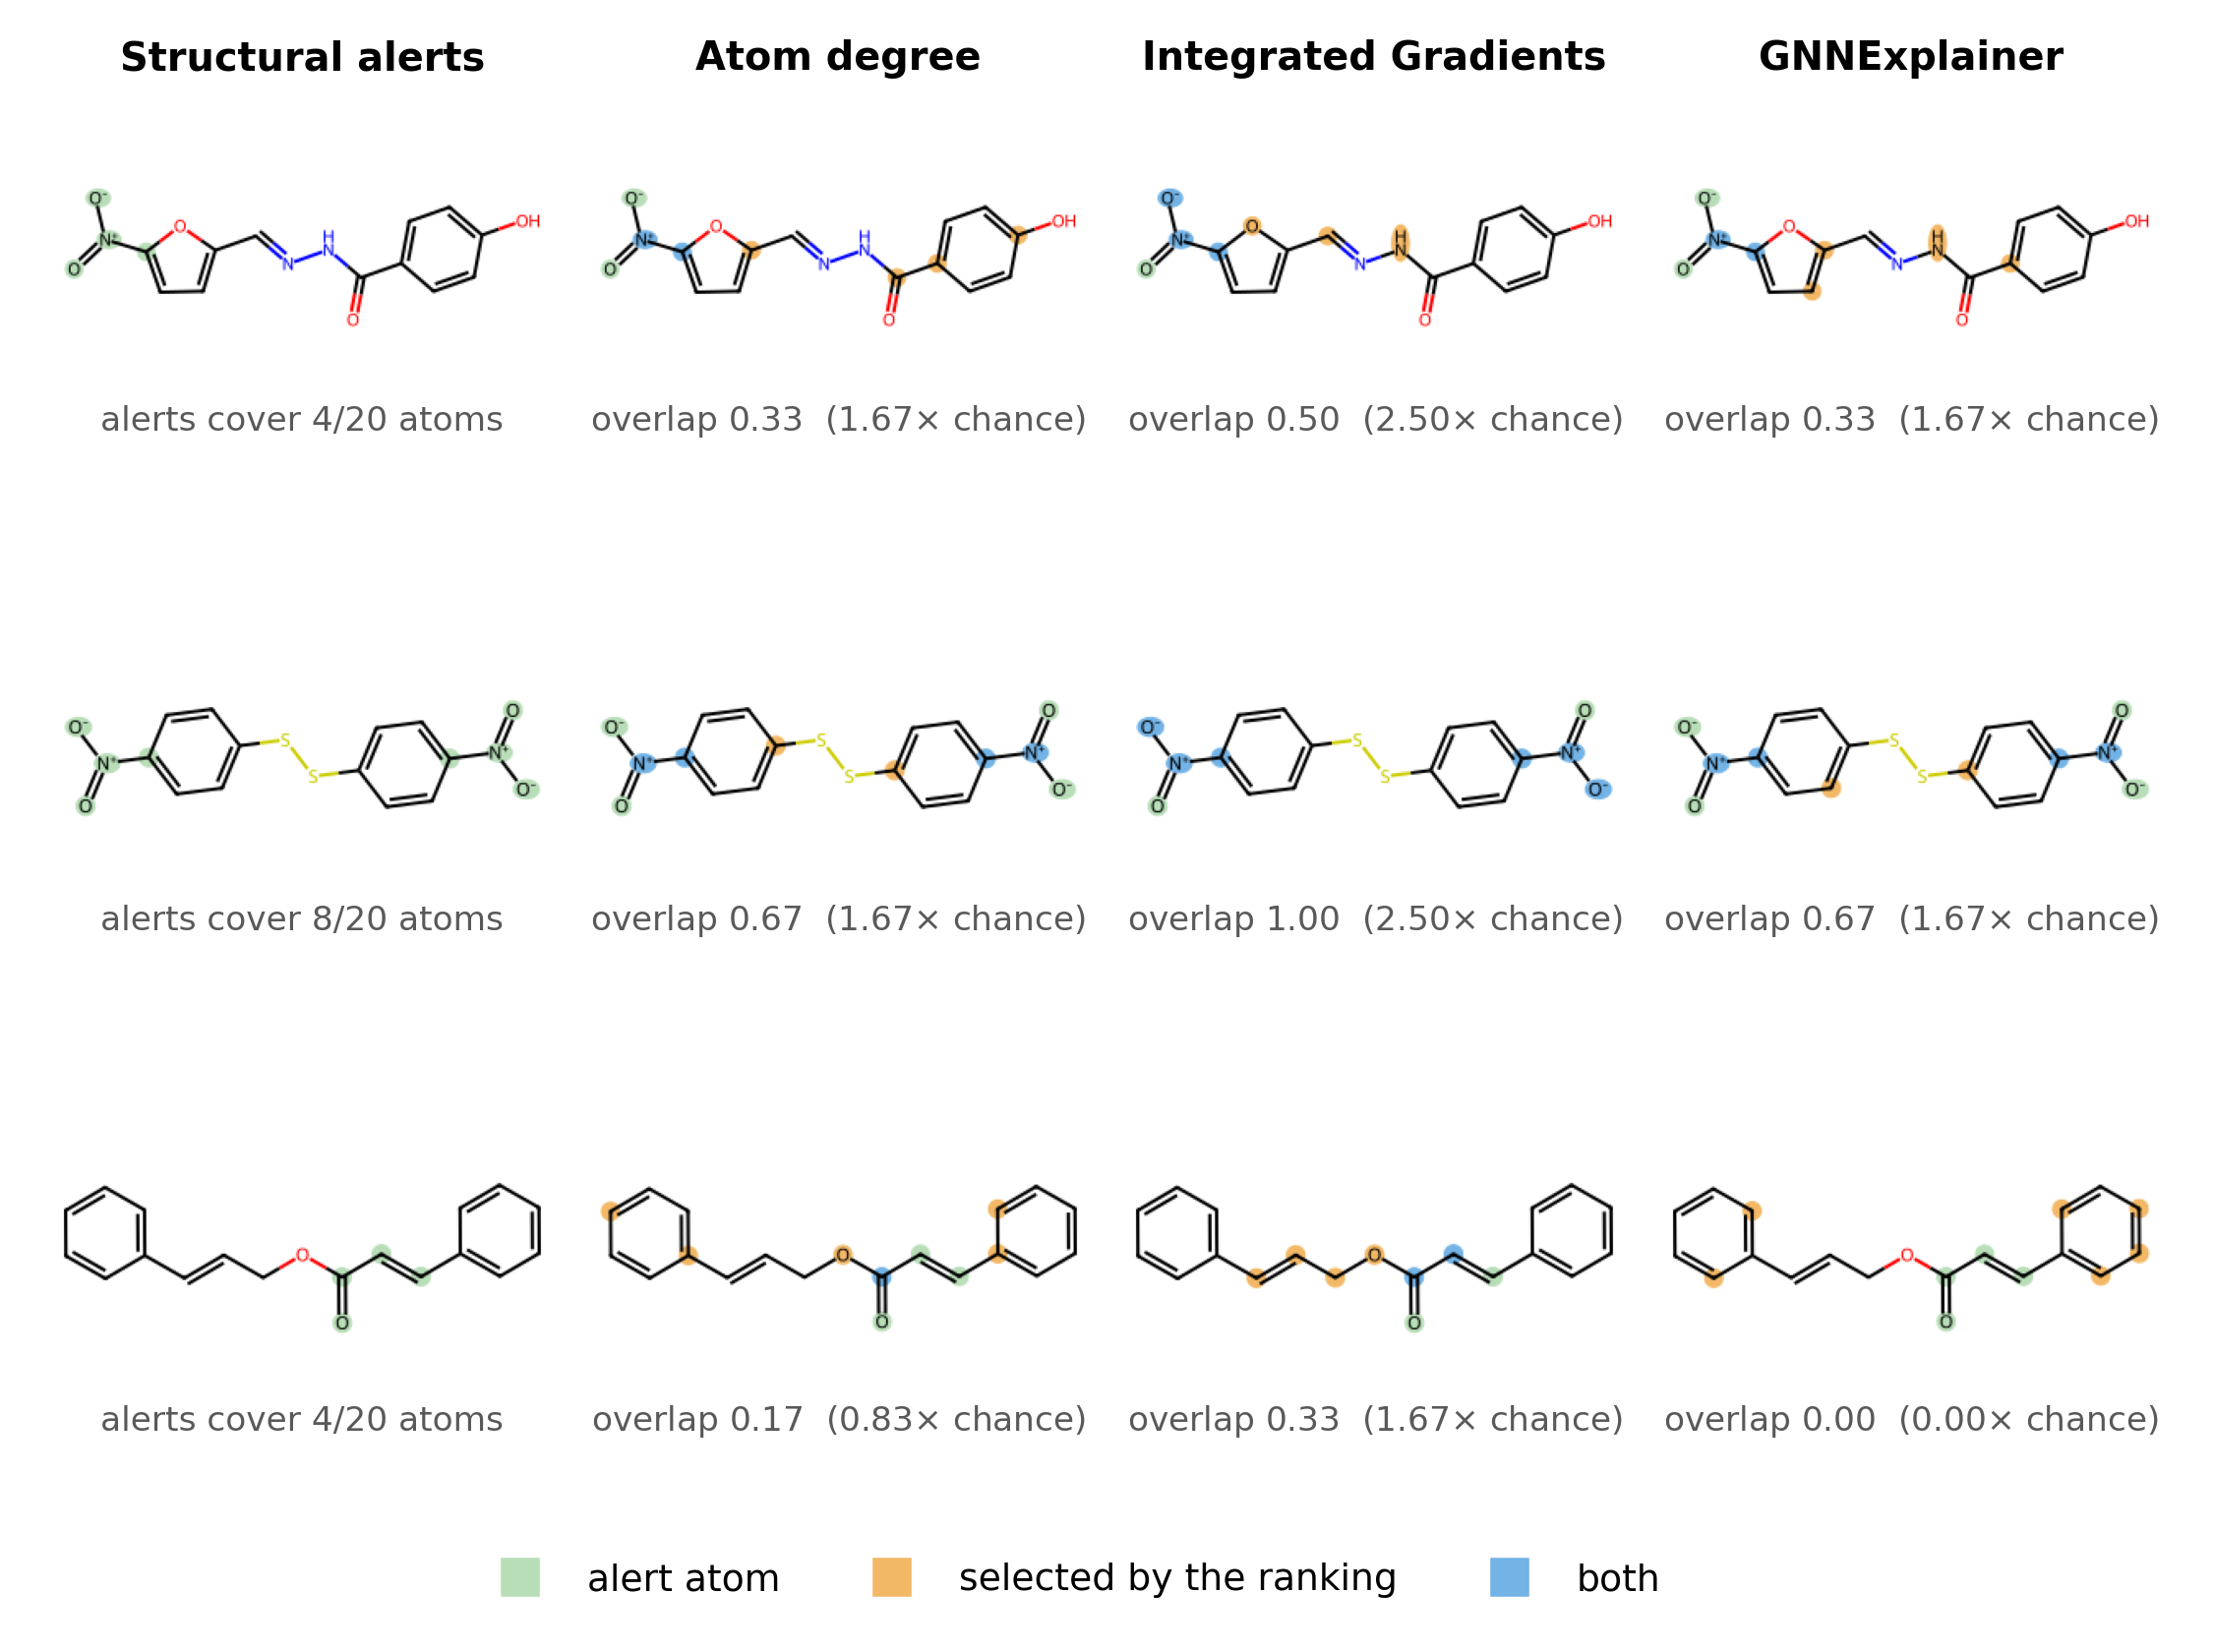

In [13]:
import sys; sys.path.insert(0,"/content")
import numpy as np, pandas as pd, json, glob
from rdkit import Chem, DataStructs
from rdkit.Chem.Scaffolds import MurckoScaffold
from collections import defaultdict
from rdkit.Chem import rdFingerprintGenerator as rfg
import f_examples

PRIMARY_SPLIT_SEED = 101
morgan = rfg.GetMorganGenerator(radius=2, fpSize=2048)

def safe_scaffold(s):
    m = Chem.MolFromSmiles(s)
    if m is None: return ""
    try: return MurckoScaffold.MurckoScaffoldSmiles(mol=m)
    except Exception:
        try: return Chem.MolToSmiles(MurckoScaffold.GetScaffoldForMol(m))
        except Exception: return s

df = pd.concat([pd.read_csv(f"{DATADIR}/{f}") for f in ["train.csv","valid.csv","test.csv"]],
               ignore_index=True)[["Drug_ID","smiles","label"]]
df["canonical"] = df["smiles"].apply(
    lambda s: Chem.MolToSmiles(Chem.MolFromSmiles(s)) if Chem.MolFromSmiles(s) else None)
df = df.dropna(subset=["canonical"]).drop_duplicates(subset="canonical", keep="first").reset_index(drop=True)
groups = defaultdict(list)
for i, s in zip(df.index, df["canonical"].map(safe_scaffold)): groups[s].append(i)
gs = list(groups.values()); rng = np.random.default_rng(PRIMARY_SPLIT_SEED)
gs.sort(key=lambda g: (-len(g), rng.random()))
n = len(df); a, b = int(.8*n), int(.9*n); tr, va, te = [], [], []
for g in gs:
    if len(tr)+len(g) <= a: tr += g
    elif len(tr)+len(va)+len(g) <= b: va += g
    else: te += g
df_test = df.loc[te].reset_index(drop=True)
assert set(df_test.canonical) == set(pd.read_csv(f"{R}/primary_test.csv").canonical)

TOX = {"aromatic_nitro":"[a][N+](=O)[O-]","aromatic_amine":"[a][NX3;H2,H1;!$(N[!#6]);!$(N=*)]",
 "aromatic_nitroso":"[a][NX2]=[OX1]","alkyl_nitrite":"[CX4][OX2][NX2]=[OX1]",
 "nitrosamine":"[NX3][NX2]=[OX1]","epoxide":"C1OC1","aziridine":"C1NC1",
 "azide":"[NX2]=[NX2+]=[NX1-]","azo_aromatic":"[a][NX2]=[NX2][a]",
 "aliphatic_halide":"[CX4][F,Cl,Br,I]","hetero_hetero_bond":"[N,O;H1,H2][N,O;H1,H2]",
 "polycyclic_aromatic":"c1ccc2ccccc2c1","aromatic_hydroxylamine":"[a][NX3;H1][OX2;H1]",
 "michael_acceptor":"[CX3]=[CX3][CX3]=[OX1]","aromatic_azoxy":"[a][NX2]=[NX3+]([O-])[a]",
 "nitrogen_mustard":"[NX3]([CX4][CX4][F,Cl,Br,I])[CX4][CX4][F,Cl,Br,I]",
 "aromatic_hydrazine":"[a][NX3;H1][NX3;H2]","alkyl_sulfonate":"[CX4][OX2][SX4](=[OX1])(=[OX1])"}
PAT = {k: Chem.MolFromSmarts(v) for k, v in TOX.items()}
EVAL = []
for smi, lab in zip(df_test.canonical, df_test.label):
    if lab != 1: continue
    mol = Chem.MolFromSmiles(smi)
    if mol is None or mol.GetNumAtoms() == 0: continue
    t = set()
    for p in PAT.values():
        for m in mol.GetSubstructMatches(p): t.update(m)
    if not t or len(t) == mol.GetNumAtoms(): continue
    EVAL.append({"smiles": smi, "mol": mol, "tox": t, "n_atoms": mol.GetNumAtoms()})
print(f"evaluation set {len(EVAL)}")

SC = {"Atom degree": [np.array([a.GetDegree() for a in e["mol"].GetAtoms()], dtype=float)
                      for e in EVAL]}
p = sorted(glob.glob(f"{EXPL}/scores_ig_seed*.npz"))
if p:
    z = np.load(p[0]); SC["Integrated Gradients"] = [z[f"m{i}"] for i in range(len(EVAL))]
p = sorted(glob.glob(f"{EXPL}/masks_default_seed*.npz")) or [f"{EXPL}/gnnexplainer_scores.npy"]
if os.path.exists(p[0]):
    SC["GNNExplainer"] = ([np.load(p[0])[f"m{i}"] for i in range(len(EVAL))]
                          if p[0].endswith(".npz") else
                          list(np.load(p[0], allow_pickle=True)))
print("rankings drawn:", list(SC))
chosen = f_examples.build(EVAL, SC, OUT)
for s, c in chosen: print(f"  {c:.2f}  {s}")
from IPython.display import Image, display
display(Image(f"{OUT}/fig06_examples.png", width=740))

## 8. Generate everything

In [14]:
import importlib, glob
import msstyle, f_ladder, f_mechanism, f_regimes, f_models, f_design, f_si, mstables, f_smarts
for m in (msstyle, f_ladder, f_mechanism, f_regimes, f_models, f_design, f_si, mstables, f_smarts):
    importlib.reload(m)

TAB = f"{WORK}/tables_ms"; os.makedirs(TAB, exist_ok=True)

print("main figures")
print("  ladder    ", f_ladder.build(R, OUT).lift.round(3).tolist())
print("  mechanism ", f_mechanism.build(R, EXPL, OUT))
piv, meta = f_regimes.build(R, OUT); print("  regimes    degree", piv.loc["degree"].round(3).tolist())
print("  models    ", f_models.build(R, OUT))
pt, rho = f_design.build(R, OUT);    print("  design     rank correlation", round(rho, 3))

print("\nsupporting figures")
f_si.protocol(R, OUT); f_si.topk(R, OUT); f_si.epoch(R, OUT)
print("  written")

print("\ntables")
num = mstables.build(R, TAB)
num.update(mstables.build_si(R, TAB))
sm = f_smarts.build(TOX, EVAL, TAB)
print(f"  {len(glob.glob(TAB + '/*.tex'))} LaTeX fragments")
print(f"  alert library: {len(sm)} patterns, widest coverage "
      f"{sm.Molecules.max()} of {len(EVAL)} molecules")

pd.DataFrame(sorted(num.items()), columns=["quantity", "value"]).to_csv(
    f"{TAB}/manuscript_numbers.csv", index=False)
print(f"  {len(num)} quantities recorded")

main figures
  ladder     [1.914, 1.542, 1.265, 1.214, 1.116, 1.086, 1.037, 1.036, 1.005, 0.98]
  mechanism  {'r_deg_un': np.float64(0.9430977749648237), 'r_deg_tr': np.float64(0.8235521715273723), 'spearman_mean': 0.5270937544768481, 'n': 237}
  regimes    degree [1.278, 1.214, 1.162]
  models     {'mean': np.float64(1.2654934072765742), 'sd': np.float64(0.09159212419131602), 'pct_above': np.float64(75.0), 'r': np.float64(0.2556762372358025), 'p': np.float64(0.27659225021689965)}
  design     rank correlation 0.657

supporting figures
  written

tables
  16 LaTeX fragments
  alert library: 18 patterns, widest coverage 97 of 237 molecules
  19 quantities recorded


## 9. Collecting the output

In [15]:
import shutil
STAGE = "/content/manuscript_assets"
shutil.rmtree(STAGE, ignore_errors=True)
os.makedirs(f"{STAGE}/figures", exist_ok=True); os.makedirs(f"{STAGE}/tables", exist_ok=True)
for f in glob.glob(f"{OUT}/*"):  shutil.copy(f, f"{STAGE}/figures/")
for f in glob.glob(f"{TAB}/*"):  shutil.copy(f, f"{STAGE}/tables/")
arc = shutil.make_archive("/content/manuscript_assets", "zip", STAGE)
print(f"{len(glob.glob(STAGE+'/figures/*.pdf'))} figures, "
      f"{len(glob.glob(STAGE+'/tables/*.tex'))} tables -> {arc}")
for f in sorted(glob.glob(STAGE+"/figures/*.pdf")): print("  -", os.path.basename(f))
for f in sorted(glob.glob(STAGE+"/tables/*.tex")):  print("  -", os.path.basename(f))
from google.colab import files
files.download(arc)

9 figures, 16 tables -> /content/manuscript_assets.zip
  - fig01_ladder.pdf
  - fig02_mechanism.pdf
  - fig03_regimes.pdf
  - fig04_models.pdf
  - fig05_design.pdf
  - fig06_examples.pdf
  - figS3_protocol.pdf
  - figS6_topk.pdf
  - figS7_epoch.pdf
  - tabS10_applicability.tex
  - tabS11_misc.tex
  - tabS12_smarts.tex
  - tabS1_data.tex
  - tabS2_hpo.tex
  - tabS3_pairwise.tex
  - tabS4_explainers.tex
  - tabS5_permutation.tex
  - tabS6_rule_representation.tex
  - tabS7_gnnexplainer.tex
  - tabS8_nullhp.tex
  - tabS9_calibration.tex
  - tab_accuracy.tex
  - tab_contrasts.tex
  - tab_controls.tex
  - tab_regimes.tex


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>